In [8]:
import xarray as xr, numpy as np
dsraw = xr.open_dataset("/glade/u/home/hmnguyen/input/cice.test.2/ocnice/ocean_hgrid_cice_test_1_d12753.nc")

i = slice(round(dsraw.dims['nx'] // 3), dsraw.dims['nx'])
j = slice(round(dsraw.dims['ny'] // 3), dsraw.dims['ny'])
print(i, j)

sub = dsraw.isel(nx=i, nxp=slice(i.start, i.stop+1),
              ny=j, nyp=slice(j.start, j.stop+1))

sub.to_netcdf("arctic_NE_hgrid.nc")

slice(360, 1080, None) slice(464, 1392, None)


In [9]:
import xarray as xr
import numpy as np

ds = xr.open_dataset("arctic_NE_hgrid.nc")

# Supergrid corner coordinates
lon_c = ds["x"].values          # shape (nyp, nxp)
lat_c = ds["y"].values

# Native-grid cell centres = every second point
lon_ctr = lon_c[1::2, 1::2]     # shape (ny, nx)
lat_ctr = lat_c[1::2, 1::2]

# Keep Cartopy happy if longitudes are 0–360
lon_ctr = np.where(lon_ctr > 180, lon_ctr - 360, lon_ctr)
lon_c   = np.where(lon_c   > 180, lon_c   - 360, lon_c)

In [10]:
import cartopy.crs as ccrs
proj = ccrs.NorthPolarStereo()       # true at the pole, good for grids ≥ 60 °N

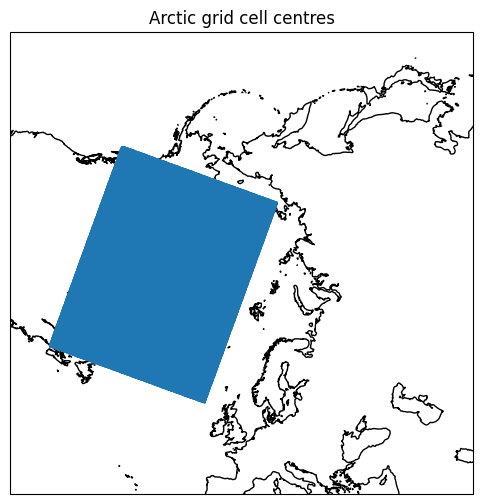

In [11]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(6,6))
ax  = plt.axes(projection=proj)
ax.set_extent([-180, 180, 40, 90], crs=ccrs.PlateCarree())

# Coastlines for context
ax.coastlines(resolution="50m")

# Quick view of cell centres
ax.scatter(lon_ctr, lat_ctr, s=1,
           transform=ccrs.PlateCarree(), zorder=3)

plt.title("Arctic grid cell centres")
plt.show()

In [10]:
from CrocoDash.grid import Grid

grid = Grid.from_supergrid("arctic_NE_hgrid.nc")

In [19]:
toporaw = xr.open_dataset("/glade/u/home/hmnguyen/input/cice.test.2/ocnice/ocean_topog_cice_test_1_d12753.nc")

# Indices of the NE quarter — exact numbers depend on what you want
i = slice(round(toporaw.dims['nx'] // 3), toporaw.dims['nx'])
j = slice(round(toporaw.dims['ny'] // 3), toporaw.dims['ny'])
print(i, j)

toposub = toporaw.isel(nx=i, ny=j)

toposub.to_netcdf("arctic_NE_topog.nc")

slice(180, 540, None) slice(232, 696, None)


In [13]:
from CrocoDash.topo import Topo
bathymetry_path='arctic_NE_topog.nc'

topo = Topo.from_topo_file(
    grid = grid,
    topo_file_path=bathymetry_path,
    min_depth = 15,
)

In [14]:
from CrocoDash.vgrid import VGrid

vgrid  = VGrid.hyperbolic(
    nk = 75,
    depth = topo.max_depth,
    ratio=20.0
)

In [15]:
from pathlib import Path

In [16]:
# CESM case (experiment) name
casename = "cice.subset.kate"

# CESM source root (Update this path accordingly!!!)
cesmroot = "/glade/work/hmnguyen/CESM"

# Place where all your input files go
inputdir = Path.home() / "input" / casename

# CESM case directory
caseroot = Path.home() / "cases" / casename
print(cesmroot, inputdir, caseroot) # View your directory and change as you need!

/glade/work/hmnguyen/CESM /glade/u/home/hmnguyen/input/cice.subset.kate /glade/u/home/hmnguyen/cases/cice.subset.kate


In [17]:
from CrocoDash.case import Case
grid.name = "pan_arctic_kate" # change name here

case = Case(
    cesmroot = cesmroot,
    caseroot = caseroot,
    inputdir = inputdir,
    ocn_grid = grid,
    ocn_vgrid = vgrid,
    ocn_topo = topo,
    project = 'P93300012', # Switch this
    override = True,
    machine = "derecho", # And this
    compset = "1850_DATM%JRA_SLND_CICE_MOM6_SROF_SGLC_SWAV", 
)

INFO:  csp_solver:CspSolver initialized.


Creating case...

• Updating ccs_config/modelgrid_aliases_nuopc.xml file to include the new resolution "cice.subset.kate" consisting of the following component grids.
 atm grid: "TL319", lnd grid: "TL319", ocn grid: "pan_arctic_kate".

• Updating ccs_config/component_grids_nuopc.xml file to include newly generated ocean grid "pan_arctic_kate" with the following properties:
 nx: 360, ny: 464. ocean mesh: /glade/u/home/hmnguyen/input/cice.subset.kate/ocnice/ESMF_mesh_pan_arctic_kate_0a2c0a.nc.

Running the create_newcase tool with the following command:

/glade/work/hmnguyen/CESM/cime/scripts/create_newcase --compset 1850_DATM%JRA_SLND_CICE_MOM6_SROF_SGLC_SWAV --res cice.subset.kate --case /glade/u/home/hmnguyen/cases/cice.subset.kate --machine derecho --run-unsupported --project P93300012 

The create_newcase command was successful.

Navigating to the case directory:

cd /glade/u/home/hmnguyen/cases/cice.subset.kate

Apply NTASK grid xml changes:

./xmlchange NTASKS_OCN=256

Running the

INFO:	stage:SUCCESS: All stages are complete.


Case created successfully at /glade/u/home/hmnguyen/cases/cice.subset.kate.

To further customize, build, and run the case, navigate to the case directory in your terminal. To create another case, restart the notebook.



In [18]:
from CrocoDash.case import Case
# Turn off tides for now - 30/06/2025
case.configure_forcings(
    date_range = ["1993-01-01 00:00:00", "1993-01-06 00:00:00"],
    #tidal_constituents = ['M2'],
    #tpxo_elevation_filepath = "/glade/u/home/hmnguyen/ncfile/h_tpxo9.v1.nc",
    #tpxo_velocity_filepath = "/glade/u/home/hmnguyen/ncfile/u_tpxo9.v1.nc",
    too_much_data = False,
)

INFO:CrocoDash.raw_data_access.datasets.glorys:This data access method retuns a script at path /glade/derecho/scratch/hmnguyen/tmp/tmp_zja_vjk/get_glorys_data.sh to run to get access data 
INFO:CrocoDash.raw_data_access.datasets.glorys:This data access method retuns a script at path /glade/u/home/hmnguyen/input/cice.subset.kate/glorys/get_glorys_data.sh to run to get access data 
INFO:CrocoDash.raw_data_access.datasets.glorys:This data access method retuns a script at path /glade/u/home/hmnguyen/input/cice.subset.kate/glorys/get_glorys_data.sh to run to get access data 
INFO:CrocoDash.raw_data_access.datasets.glorys:This data access method retuns a script at path /glade/u/home/hmnguyen/input/cice.subset.kate/glorys/get_glorys_data.sh to run to get access data 
INFO:CrocoDash.raw_data_access.datasets.glorys:This data access method retuns a script at path /glade/u/home/hmnguyen/input/cice.subset.kate/glorys/get_glorys_data.sh to run to get access data 
INFO:CrocoDash.raw_data_access.data

In [ ]:
# Run cp /glade/derecho/scratch/manishrv/croc_input/cice.test.1/ocnice/{forcing_*,tu_*,tz_*} ~/input/cice.test.2/ocnice/
# Go to ~/input/cice.test.2/glorys and run "cp get_glorys_data.sh get_glorys_ic_fixed.sh"
# Run chmod +x get_glorys_data.sh and chmod +x get_glorys_ic_fixed.sh
# Run get_glorys_data.sh as normal in CrocoDash env (run conda activate CrocoDash first)
# Run "nano get_glorys_ic_fixed.sh" and comment out the first 4 copernicus commands. Change the --maximum-latitude param to less than 90 i.e. ~89.99999999

In [19]:
case.process_forcings(
    process_velocity_tracers = True, 
    process_initial_condition = True, 
    process_tides = False, # No tides for now
)

INFO:regional_mom6.regridding:Getting t points..
INFO:regional_mom6.regridding:Creating Regridder
INFO:regional_mom6.regridding:Creating Regridder
INFO:regional_mom6.regridding:Creating Regridder


Setting up Initial Conditions
Regridding Velocities... 

INFO:regional_mom6.rotation:Getting rotation angle
INFO:regional_mom6.rotation:Calculating grid rotation angle
INFO:regional_mom6.regridding:Getting u points..
INFO:regional_mom6.regridding:Getting v points..


Done.
Regridding Tracers... Done.
Regridding Free surface... Done.
Saving outputs... 

INFO:regional_mom6.regridding:Creating coordinates of the boundary q/u/v points
INFO:regional_mom6.regridding:Creating Regridder


...

Done.
Processing west boundary velocity & tracers...

INFO:regional_mom6.rotation:Getting rotation angle
INFO:regional_mom6.rotation:Calculating grid rotation angle
INFO:regional_mom6.regridding:Creating coordinates of the boundary q/u/v points
INFO:regional_mom6.regridding:Filling in missing data horizontally, then vertically
INFO:regional_mom6.regridding:Adding time dimension
INFO:regional_mom6.regridding:Renaming vertical coordinate to nz_... in salt_segment_003
INFO:regional_mom6.regridding:Replacing old depth coordinates with incremental integers
INFO:regional_mom6.regridding:Adding perpendicular dimension to salt_segment_003
INFO:regional_mom6.regridding:Renaming vertical coordinate to nz_... in temp_segment_003
INFO:regional_mom6.regridding:Replacing old depth coordinates with incremental integers
INFO:regional_mom6.regridding:Adding perpendicular dimension to temp_segment_003
INFO:regional_mom6.regridding:Renaming vertical coordinate to nz_... in u_segment_003
INFO:regional_mom6.regridding:Replacing old depth coordinates with incr

Done.
Processing east boundary velocity & tracers...

INFO:regional_mom6.rotation:Getting rotation angle
INFO:regional_mom6.rotation:Calculating grid rotation angle
INFO:regional_mom6.regridding:Creating coordinates of the boundary q/u/v points
INFO:regional_mom6.regridding:Filling in missing data horizontally, then vertically
INFO:regional_mom6.regridding:Adding time dimension
INFO:regional_mom6.regridding:Renaming vertical coordinate to nz_... in salt_segment_004
INFO:regional_mom6.regridding:Replacing old depth coordinates with incremental integers
INFO:regional_mom6.regridding:Adding perpendicular dimension to salt_segment_004
INFO:regional_mom6.regridding:Renaming vertical coordinate to nz_... in temp_segment_004
INFO:regional_mom6.regridding:Replacing old depth coordinates with incremental integers
INFO:regional_mom6.regridding:Adding perpendicular dimension to temp_segment_004
INFO:regional_mom6.regridding:Renaming vertical coordinate to nz_... in u_segment_004
INFO:regional_mom6.regridding:Replacing old depth coordinates with incr

Done.
Adding parameter changes to user_nl_mom:

  ! Initial conditions
  INIT_LAYERS_FROM_Z_FILE = True
  TEMP_SALT_Z_INIT_FILE = init_tracers.nc
  Z_INIT_FILE_PTEMP_VAR = temp
  Z_INIT_ALE_REMAPPING = True
  TEMP_SALT_INIT_VERTICAL_REMAP_ONLY = True
  DEPRESS_INITIAL_SURFACE = True
  SURFACE_HEIGHT_IC_FILE = init_eta.nc
  SURFACE_HEIGHT_IC_VAR = eta_t
  VELOCITY_CONFIG = file
  VELOCITY_FILE = init_vel.nc

  ! Open boundary conditions
  OBC_NUMBER_OF_SEGMENTS = 4
  OBC_FREESLIP_VORTICITY = False
  OBC_FREESLIP_STRAIN = False
  OBC_COMPUTED_VORTICITY = True
  OBC_COMPUTED_STRAIN = True
  OBC_ZERO_BIHARMONIC = True
  OBC_TRACER_RESERVOIR_LENGTH_SCALE_OUT = 3.0E+04
  OBC_TRACER_RESERVOIR_LENGTH_SCALE_IN = 3000.0
  BRUSHCUTTER_MODE = True
  OBC_SEGMENT_001 = "J=0,I=0:N,FLATHER,ORLANSKI,NUDGED,ORLANSKI_TAN,NUDGED_TAN"
  OBC_SEGMENT_001_VELOCITY_NUDGING_TIMESCALES = 0.3, 360.0
  OBC_SEGMENT_001_DATA = "U=file:forcing_obc_segment_001.nc(u),V=file:forcing_obc_segment_001.nc(v),SSH=file:forcin

## Slicing ICs

In [4]:
import xarray as xr, numpy as np
ic   = xr.open_dataset("/glade/u/home/hmnguyen/input/cice.test.2/ocnice/glorys_ic_75z_1993.nc")
#dsgrid = xr.open_dataset("/glade/u/home/hmnguyen/input/cice.test.2/ocnice/ocean_hgrid_cice_test_1_d12753.nc")
nx, ny = ic.dims["xh"], ic.dims["yh"]   # native-grid sizes

istart, iend = int(nx/3), nx        # last 2/3 of the domain
jstart, jend = int(ny/3), ny

/glade/work/hmnguyen/conda-envs/CrocoDashCartopy/lib/python3.12/site-packages/xarray/core/utils.py:494: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  warnings.warn(


In [5]:
import xarray as xr, pathlib as pl
i_T  = slice(istart, iend)          # T cells  (xh)
i_U  = slice(istart, iend+1)        # U cells  (xq = xh+1)
j_T  = slice(jstart, jend)          # T cells  (yh)
j_V  = slice(jstart, jend+1)        # V cells  (yq = yh+1)

ic_sub = ic.isel(
    xh=i_T, xq=i_U,
    yh=j_T, yq=j_V
)
ic_sub.to_netcdf("glorys_ic_75z_1993_2div3.nc")

## Copy Kate's MOM input

In [7]:
import shutil

source_file = "/glade/derecho/scratch/manishrv/pan_artic_files_kate/MOM_input"
destination_file = "/glade/u/home/hmnguyen/cases/cice.subset.kate/SourceMods/src.mom/MOM_input"
shutil.copy(source_file, destination_file)

'/glade/u/home/hmnguyen/cases/cice.subset.kate/SourceMods/src.mom/MOM_input'